In [2]:
import pandas as pd
import numpy as np
from google.colab import files

subido = files.upload()   # selecciona Sales_transactions_2022_2025.csv
df = pd.read_csv("Sales_transactions_2022_2025.csv")
print("Filas y columnas originales:", df.shape)

# 1. Duplicados
n0 = len(df)
df = df.drop_duplicates()
print("Duplicados eliminados:", n0 - len(df))

# 2. Texto inconsistente (mayúsculas, espacios)
df["Product_Category"] = df["Product_Category"].str.strip().str.title()
df["Sales_Channel"] = df["Sales_Channel"].str.strip()
print(df["Product_Category"].value_counts())
print(df["Sales_Channel"].value_counts())

# 3. Cantidades imposibles (cero o negativas)
print("Cantidades <= 0:", (df["Quantity"] <= 0).sum())
df = df[df["Quantity"] > 0]

# 4. Nulos en las 6 variables del estudio
cols = ["Sales_Channel", "Product_Category", "Quantity",
        "Delivery_Days", "Sales_Amount", "Profit"]
print(df[cols].isnull().sum())
df = df.dropna(subset=cols)

# 5. Coherencia: Profit debe ser Sales_Amount - Cost_Amount
dif = (df["Profit"] - (df["Sales_Amount"] - df["Cost_Amount"])).abs()
print("Filas donde Profit no cuadra:", (dif > 0.01).sum())

# 6. Tipos correctos y archivo final
df["Delivery_Days"] = df["Delivery_Days"].astype(int)
limpio = df[cols].copy()
print("Filas y columnas limpias:", limpio.shape)

limpio.to_csv("ventas_limpio.csv", index=False)
files.download("ventas_limpio.csv")

Saving Sales_transactions_2022_2025.csv to Sales_transactions_2022_2025.csv
Filas y columnas originales: (18045, 36)
Duplicados eliminados: 45
Product_Category
Electronics        8188
Office Supplies    4524
Furniture          3303
Appliances         1985
Name: count, dtype: int64
Sales_Channel
Online          8195
Retail Store    6221
B2B Portal      2124
Phone Order     1460
Name: count, dtype: int64
Cantidades <= 0: 8
Sales_Channel         0
Product_Category      0
Quantity              0
Delivery_Days       162
Sales_Amount          0
Profit                0
dtype: int64
Filas donde Profit no cuadra: 2158
Filas y columnas limpias: (17830, 6)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving ventas_limpio.csv to ventas_limpio (1).csv

Tabla de frecuencias: Sales_Channel
               Frecuencia absoluta  Frecuencia relativa  Porcentaje (%)  \
Sales_Channel                                                             
Online                        8115               0.4551           45.51   
Retail Store                  6168               0.3459           34.59   
B2B Portal                    2111               0.1184           11.84   
Phone Order                   1436               0.0805            8.05   

               Frecuencia acumulada  Porcentaje acumulado (%)  
Sales_Channel                                                  
Online                         8115                     45.51  
Retail Store                  14283                     80.11  
B2B Portal                    16394                     91.95  
Phone Order                   17830                    100.00  

Tabla de frecuencias: Product_Category
                  Frecuencia absoluta 

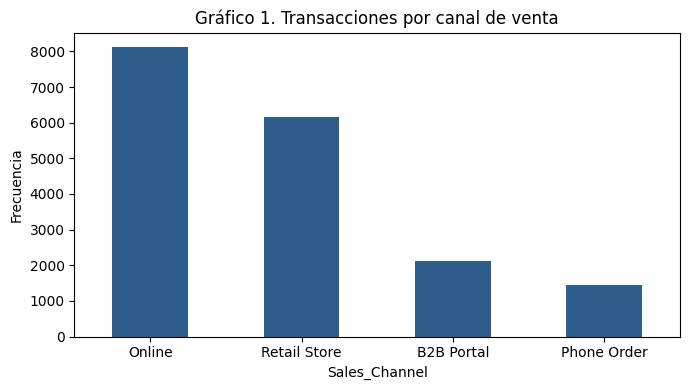

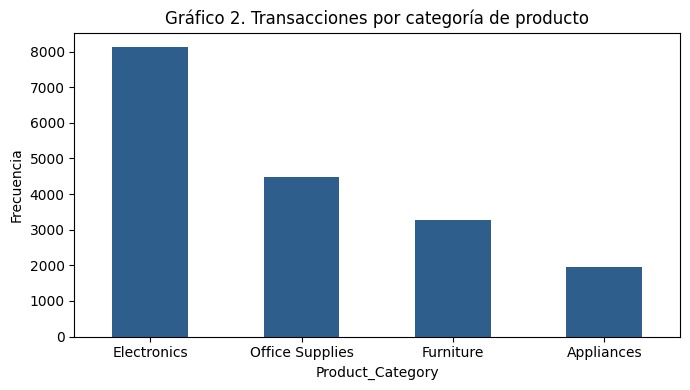

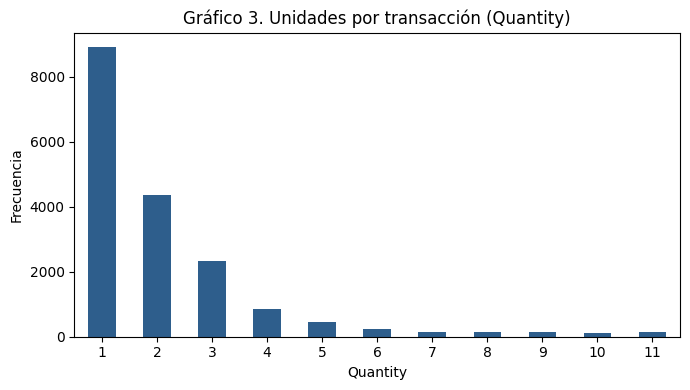

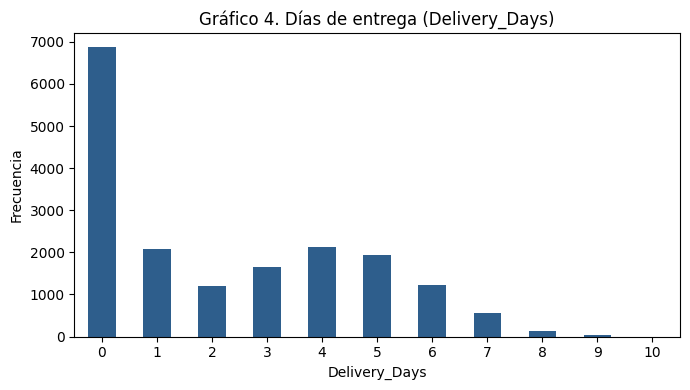

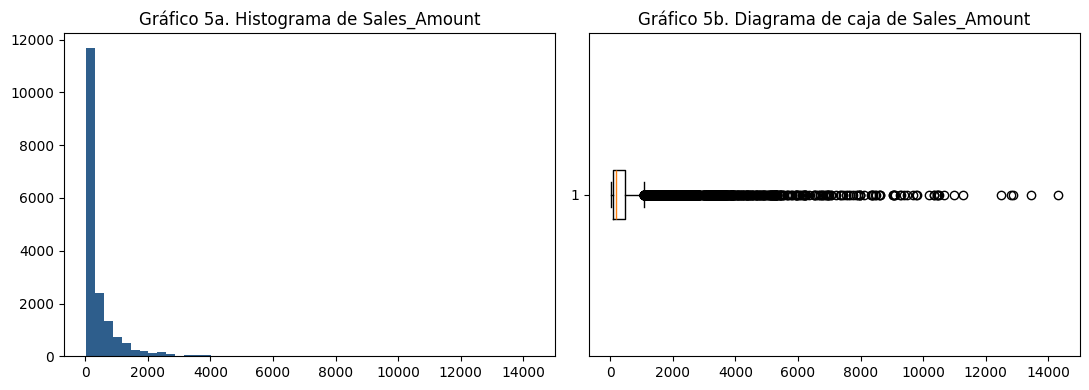

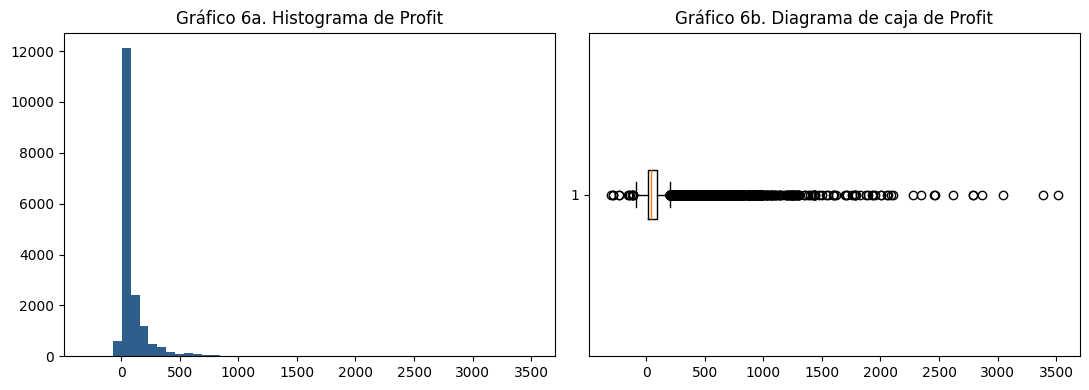

                     Quantity  Delivery_Days  Sales_Amount    Profit
Media                    2.13           2.26        457.14     91.35
Mediana                  2.00           1.00        168.68     40.17
Moda                     1.00           0.00         68.65     10.01
Mínimo                   1.00           0.00         16.68   -299.31
Máximo                  11.00          10.00      14303.07   3512.08
Rango                   10.00          10.00      14286.39   3811.39
Q1                       1.00           0.00         78.52     19.47
Q3                       3.00           4.00        471.61     93.28
RIC                      2.00           4.00        393.10     73.81
Varianza                 3.19           5.39     736208.31  28199.39
Desv. estándar           1.78           2.32        858.03    167.93
Coef. variación (%)     83.96         102.63        187.69    183.82
Asimetría                2.62           0.57          5.74      6.63
Curtosis                 8.03     

In [3]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from google.colab import files

files.upload()   # ventas_limpio.csv
df = pd.read_csv("ventas_limpio.csv")

# ---------- Tablas de frecuencia (cualitativas) ----------
for col in ["Sales_Channel", "Product_Category"]:
    f = df[col].value_counts()
    tabla = pd.DataFrame({
        "Frecuencia absoluta": f,
        "Frecuencia relativa": (f / len(df)).round(4),
        "Porcentaje (%)": (f / len(df) * 100).round(2),
        "Frecuencia acumulada": f.cumsum(),
        "Porcentaje acumulado (%)": (f.cumsum() / len(df) * 100).round(2),
    })
    print(f"\nTabla de frecuencias: {col}")
    print(tabla)

# ---------- Gráficas (6) ----------
fig, ax = plt.subplots(figsize=(7, 4))
df["Sales_Channel"].value_counts().plot(kind="bar", ax=ax, color="#2E5E8C")
ax.set_title("Gráfico 1. Transacciones por canal de venta"); ax.set_ylabel("Frecuencia")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("g1.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
df["Product_Category"].value_counts().plot(kind="bar", ax=ax, color="#2E5E8C")
ax.set_title("Gráfico 2. Transacciones por categoría de producto"); ax.set_ylabel("Frecuencia")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("g2.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
df["Quantity"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#2E5E8C")
ax.set_title("Gráfico 3. Unidades por transacción (Quantity)"); ax.set_ylabel("Frecuencia")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("g3.png", dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
df["Delivery_Days"].value_counts().sort_index().plot(kind="bar", ax=ax, color="#2E5E8C")
ax.set_title("Gráfico 4. Días de entrega (Delivery_Days)"); ax.set_ylabel("Frecuencia")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("g4.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["Sales_Amount"], bins=50, color="#2E5E8C")
ax[0].set_title("Gráfico 5a. Histograma de Sales_Amount")
ax[1].boxplot(df["Sales_Amount"], vert=False)
ax[1].set_title("Gráfico 5b. Diagrama de caja de Sales_Amount")
plt.tight_layout(); plt.savefig("g5.png", dpi=200); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(df["Profit"], bins=50, color="#2E5E8C")
ax[0].set_title("Gráfico 6a. Histograma de Profit")
ax[1].boxplot(df["Profit"], vert=False)
ax[1].set_title("Gráfico 6b. Diagrama de caja de Profit")
plt.tight_layout(); plt.savefig("g6.png", dpi=200); plt.show()

# ---------- Medidas descriptivas ----------
def medidas(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return pd.Series({
        "Media": s.mean(), "Mediana": s.median(), "Moda": s.mode()[0],
        "Mínimo": s.min(), "Máximo": s.max(), "Rango": s.max() - s.min(),
        "Q1": q1, "Q3": q3, "RIC": iqr,
        "Varianza": s.var(), "Desv. estándar": s.std(),
        "Coef. variación (%)": s.std() / s.mean() * 100,
        "Asimetría": s.skew(), "Curtosis": s.kurt(),
        "Atípicos (n)": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(),
    })

resumen = df[["Quantity", "Delivery_Days", "Sales_Amount", "Profit"]].apply(medidas).round(2)
print(resumen)
resumen.to_csv("medidas_descriptivas.csv")

Tabla de contingencia (frecuencias)
Product_Category  Appliances  Electronics  Furniture  Office Supplies  Total
Sales_Channel                                                               
B2B Portal               239          962        385              525   2111
Online                   871         3661       1510             2073   8115
Phone Order              175          675        253              333   1436
Retail Store             681         2822       1127             1538   6168
Total                   1966         8120       3275             4469  17830

Porcentaje por fila (dentro de cada canal)
Product_Category  Appliances  Electronics  Furniture  Office Supplies
Sales_Channel                                                        
B2B Portal             11.32        45.57      18.24            24.87
Online                 10.73        45.11      18.61            25.55
Phone Order            12.19        47.01      17.62            23.19
Retail Store           11.04   

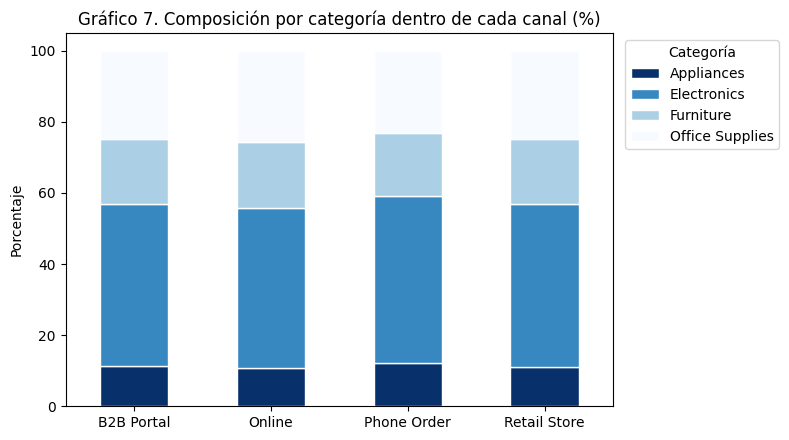


Totales por canal
               Sales_Amount    Profit
Sales_Channel                        
Online            3082494.0  623478.0
Retail Store      2417960.0  481769.0
B2B Portal        2108631.0  416828.0
Phone Order        541720.0  106737.0


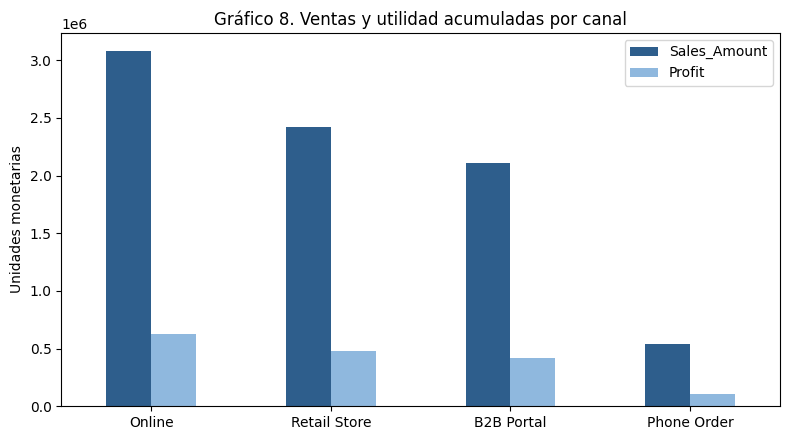


Pearson r = 0.9174 (p = 0)
Spearman rho = 0.8868 (p = 0)
Recta: Profit = 9.28 + 0.1795 * Sales_Amount | R² = 0.8416


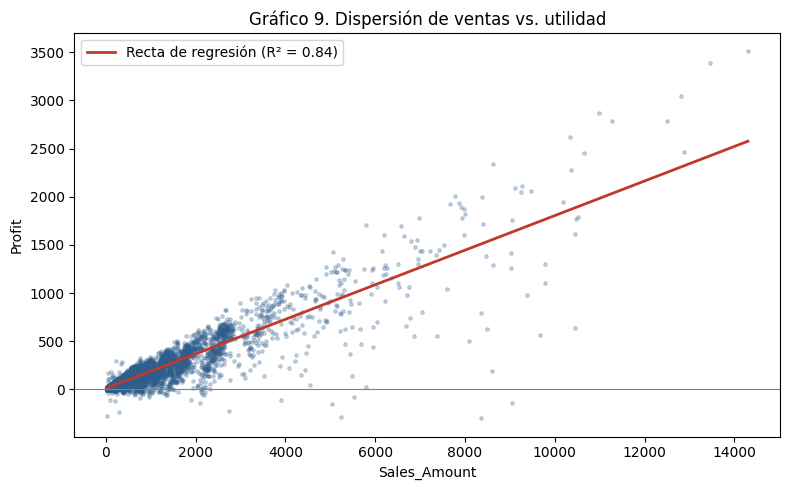

In [4]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("ventas_limpio.csv")

# ---------- 1. Dos cualitativas: canal vs. categoría ----------
cont = pd.crosstab(df["Sales_Channel"], df["Product_Category"], margins=True, margins_name="Total")
print("Tabla de contingencia (frecuencias)")
print(cont)

pct_fila = (pd.crosstab(df["Sales_Channel"], df["Product_Category"], normalize="index") * 100).round(2)
print("\nPorcentaje por fila (dentro de cada canal)")
print(pct_fila)

pct_total = (pd.crosstab(df["Sales_Channel"], df["Product_Category"], normalize="all") * 100).round(2)
print("\nPorcentaje sobre el total")
print(pct_total)

# Prueba de independencia y fuerza de la asociación
tabla = pd.crosstab(df["Sales_Channel"], df["Product_Category"])
chi2, p, gl, esp = stats.chi2_contingency(tabla)
n = tabla.values.sum()
v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
print(f"\nChi-cuadrado = {chi2:.2f}, gl = {gl}, p-valor = {p:.4f}, V de Cramér = {v:.4f}")

# Gráfico 7: barras apiladas al 100 %
fig, ax = plt.subplots(figsize=(8, 4.5))
pct_fila.plot(kind="bar", stacked=True, ax=ax, colormap="Blues_r", edgecolor="white")
ax.set_title("Gráfico 7. Composición por categoría dentro de cada canal (%)")
ax.set_ylabel("Porcentaje"); ax.set_xlabel("")
ax.legend(title="Categoría", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("g7.png", dpi=200); plt.show()

# Gráfico 8: ventas y utilidad totales por canal
tot = df.groupby("Sales_Channel")[["Sales_Amount", "Profit"]].sum().sort_values("Sales_Amount", ascending=False)
print("\nTotales por canal"); print(tot.round(0))
tot.plot(kind="bar", figsize=(8, 4.5), color=["#2E5E8C", "#8FB8DE"])
plt.title("Gráfico 8. Ventas y utilidad acumuladas por canal")
plt.ylabel("Unidades monetarias"); plt.xlabel(""); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig("g8.png", dpi=200); plt.show()

# ---------- 2. Dos cuantitativas: Sales_Amount vs. Profit ----------
pearson, p_p = stats.pearsonr(df["Sales_Amount"], df["Profit"])
spearman, p_s = stats.spearmanr(df["Sales_Amount"], df["Profit"])
print(f"\nPearson r = {pearson:.4f} (p = {p_p:.4g})")
print(f"Spearman rho = {spearman:.4f} (p = {p_s:.4g})")

pend, inter, r, _, _ = stats.linregress(df["Sales_Amount"], df["Profit"])
print(f"Recta: Profit = {inter:.2f} + {pend:.4f} * Sales_Amount | R² = {r**2:.4f}")

# Gráfico 9: dispersión con recta
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(df["Sales_Amount"], df["Profit"], s=6, alpha=0.25, color="#2E5E8C")
x = np.linspace(df["Sales_Amount"].min(), df["Sales_Amount"].max(), 100)
ax.plot(x, inter + pend * x, color="#C0392B", linewidth=2, label=f"Recta de regresión (R² = {r**2:.2f})")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_title("Gráfico 9. Dispersión de ventas vs. utilidad")
ax.set_xlabel("Sales_Amount"); ax.set_ylabel("Profit"); ax.legend()
plt.tight_layout(); plt.savefig("g9.png", dpi=200); plt.show()

In [6]:
cat = df.groupby("Product_Category")[["Sales_Amount", "Profit"]].sum()
cat["Margen (%)"] = (cat["Profit"] / cat["Sales_Amount"] * 100).round(2)
cat["% de las ventas"] = (cat["Sales_Amount"] / cat["Sales_Amount"].sum() * 100).round(2)
print(cat.sort_values("Sales_Amount", ascending=False).round(2))

                  Sales_Amount     Profit  Margen (%)  % de las ventas
Product_Category                                                      
Electronics         4885365.40  944852.83       19.34            59.94
Furniture           1958979.06  414476.23       21.16            24.03
Office Supplies      729439.47  142360.59       19.52             8.95
Appliances           577021.48  127122.25       22.03             7.08
